In [32]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score, confusion_matrix
import xgb_utils
import numpy as np
import pandas as pd
import os
import uproot
import awkward as ak
import sys
import matplotlib.pyplot as plt
import mplhep as hep
import seaborn as sns
%matplotlib inline

In [11]:
!nvidia-smi

Thu Jul 16 21:38:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          On  |   00000000:07:00.0 Off |                   On |
| N/A   36C    P0             89W /  300W |                  N/A   |     N/A      Default |
|                                         |                        |              Enabled |
+-----------------------------------------+-----

In [37]:
def plot_confusion_matrix(y_true, y_pred, labels=['ggH', 'VBF']):
    """
    Plot confusion matrix normalized by the true class (rows).
    Each row sums to 100%.
    """
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # Normalize each row
    cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm_percent,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=labels,
        yticklabels=labels,
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (%)")
    plt.show()

In [13]:
bdt_variables = [
    "diJet_mass",
    "pt_balance",
    "pt_centrality",
    "leading_jet_eta",
    "subleading_jet_eta",
    "delta_eta_diJet",
    "delta_phi_diJet",
    "n_jet",
    "leading_jet_pt",
    "subleading_jet_pt",
    "min_delta_eta_diMuon_jet",
    "min_delta_phi_diMuon_jet",
    "is_ggH_category",
    "is_VBF_category",
    "weight",
    "HT",
]

ggH_file_name= f"../../root_io/tuples/ggH_Combined_tuples.root"
VBF_file_name= f"../../root_io/tuples/VBF_Combined_tuples.root"
with uproot.open(ggH_file_name) as file:
    ggH = file["tree_output"].arrays(bdt_variables)
with uproot.open(VBF_file_name) as file:
    VBF = file["tree_output"].arrays(bdt_variables)

ggH_df = ak.to_dataframe(ggH).reset_index(drop=True)
VBF_df = ak.to_dataframe(VBF).reset_index(drop=True)

In [14]:
VBF_df[VBF_df.diJet_mass > 0]

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet,is_ggH_category,is_VBF_category,weight,HT
1,1154.75000,0.107330,1.422852,1.539795,-4.395508,5.935547,-0.755371,2,83.25000,42.50000,2.851074,2.729980,0,1,0.000028,250.468750
2,771.87500,0.055237,0.260620,1.955566,-1.760986,3.716797,-2.335449,2,219.50000,63.71875,1.353516,1.137451,0,1,0.000018,271.687500
3,491.81250,0.071182,0.398926,0.242767,-3.820801,4.063477,-2.905762,2,136.37500,29.40625,2.345215,0.444458,0,1,0.000017,317.000000
4,153.00000,0.045097,0.288940,-3.265137,-0.782959,2.482422,-2.470215,2,55.12500,30.81250,0.764771,1.169678,1,0,0.000016,151.031250
5,228.96875,0.040634,0.316711,1.542969,-0.168823,1.711914,-2.235352,2,98.25000,75.68750,0.494629,1.726807,1,0,0.000015,203.250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5154290,680.12500,0.334717,0.574463,2.805176,-1.603516,4.409180,-2.040527,3,103.62500,53.71875,1.767334,1.747070,0,1,0.000061,183.437500
5154291,1051.25000,0.099930,0.390015,2.406250,-2.985840,5.392578,1.213623,2,113.56250,44.43750,2.544922,2.279297,0,1,0.000012,253.218750
5154292,839.75000,0.015095,0.781494,0.170807,-3.326172,3.497070,-0.899292,3,238.87500,91.00000,1.408447,2.447754,0,1,0.000048,521.875000
5154295,322.50000,0.216187,1.038330,-1.282715,2.888184,4.170898,1.703613,2,46.40625,34.40625,1.430908,2.198730,1,0,0.000031,72.046875


In [15]:
ggH_events = ggH_df.weight.sum()
VBF_events = VBF_df.weight.sum()

print("ggH events: " + str(ggH_events))
print("VBF events: " + str(VBF_events))

ggH events: 1794.901233411516
VBF events: 139.59498412154528


In [16]:
ggH_df["y_truth"] = 0
VBF_df["y_truth"] = 1

In [42]:
len(VBF_df[VBF_df.n_jet < 2])

1814496

In [17]:
bdt_variables[:-4]

['diJet_mass',
 'pt_balance',
 'pt_centrality',
 'leading_jet_eta',
 'subleading_jet_eta',
 'delta_eta_diJet',
 'delta_phi_diJet',
 'n_jet',
 'leading_jet_pt',
 'subleading_jet_pt',
 'min_delta_eta_diMuon_jet',
 'min_delta_phi_diMuon_jet']

In [19]:
bdt_df = pd.concat(
    [ggH_df, VBF_df],
    ignore_index=True,
)

neither = (
    (bdt_df["is_ggH_category"] == 0) &
    (bdt_df["is_VBF_category"] == 0)
)
bdt_df = bdt_df[~neither]

X = bdt_df[bdt_variables[:-4]]
Y = bdt_df["y_truth"]

In [20]:
isggH = bdt_df["is_ggH_category"]
isVBF = bdt_df["is_VBF_category"]

In [21]:
orthogonal = (isggH + isVBF) == 1
len(orthogonal[orthogonal == False])

0

In [22]:
y_pred_kinematic = 1 - bdt_df["is_ggH_category"]

In [25]:
y_pred_kinematic

0          0
1          0
2          0
3          0
4          0
          ..
7738264    0
7738265    0
7738266    0
7738267    1
7738268    0
Name: is_ggH_category, Length: 7321932, dtype: uint32

In [26]:
Y

0          0
1          0
2          0
3          0
4          0
          ..
7738264    1
7738265    1
7738266    1
7738267    1
7738268    1
Name: y_truth, Length: 7321932, dtype: int64

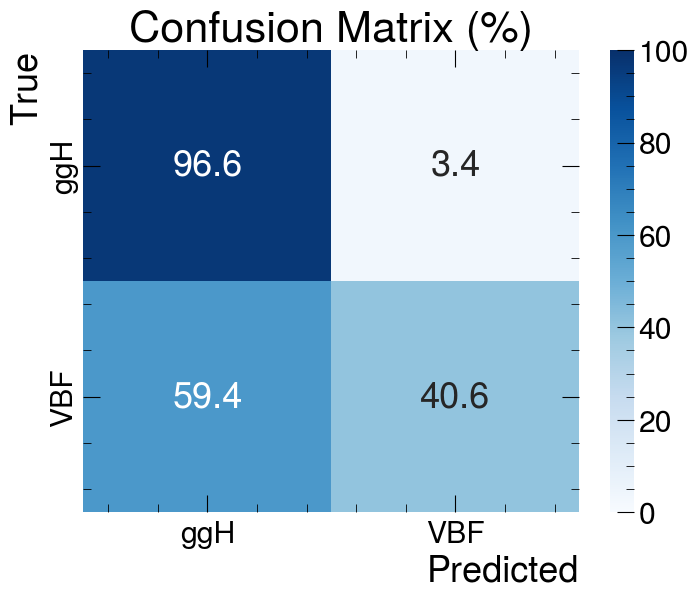

In [38]:
plot_confusion_matrix(Y, y_pred_kinematic)

In [39]:
bdt_df

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet,is_ggH_category,is_VBF_category,weight,HT,y_truth
0,0.0,-1.000000,-1.000000,-1.828613,0.000000,0.000000,-1.000000,1,28.609375,0.00000,3.175293,-3.126953,1,0,0.000740,131.312500,0
1,0.0,-1.000000,-1.000000,3.854492,0.000000,0.000000,-1.000000,1,35.656250,0.00000,1.763184,2.910645,1,0,0.000427,147.812500,0
2,0.0,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.00000,0.000000,0.000000,1,0,0.000713,127.984375,0
3,0.0,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.00000,0.000000,0.000000,1,0,0.000306,164.375000,0
4,0.0,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.00000,0.000000,0.000000,1,0,0.000166,132.968750,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7738264,322.5,0.216187,1.038330,-1.282715,2.888184,4.170898,1.703613,2,46.406250,34.40625,1.430908,2.198730,1,0,0.000031,72.046875,1
7738265,0.0,-1.000000,-1.000000,3.289062,0.000000,0.000000,-1.000000,1,62.125000,0.00000,1.499268,-3.005859,1,0,0.000034,181.812500,1
7738266,0.0,-1.000000,-1.000000,3.735840,0.000000,0.000000,-1.000000,1,33.500000,0.00000,0.370239,-3.020020,1,0,0.000034,83.328125,1
7738267,1588.5,0.032066,0.288513,2.059570,-4.115234,6.174805,-2.544922,3,149.500000,35.00000,0.510132,0.777466,0,1,0.000029,309.812500,1


In [47]:
SEED = 7
TEST_SIZE = 0.4
SAMPLE_SIZE = 1.0
x_train, x_test, y_train, y_test = train_test_split(
    X.values,
    Y.values,
    train_size=SAMPLE_SIZE * (1 - TEST_SIZE),
    test_size=SAMPLE_SIZE * TEST_SIZE,
    random_state=SEED,
)

In [48]:
X

,diJet_mass,pt_balance,pt_centrality,leading_jet_eta,subleading_jet_eta,delta_eta_diJet,delta_phi_diJet,n_jet,leading_jet_pt,subleading_jet_pt,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet
0,0.0,-1.000000,-1.000000,-1.828613,0.000000,0.000000,-1.000000,1,28.609375,0.00000,3.175293,-3.126953
1,0.0,-1.000000,-1.000000,3.854492,0.000000,0.000000,-1.000000,1,35.656250,0.00000,1.763184,2.910645
2,0.0,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.00000,0.000000,0.000000
3,0.0,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.00000,0.000000,0.000000
4,0.0,-1.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0,0.000000,0.00000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
7738264,322.5,0.216187,1.038330,-1.282715,2.888184,4.170898,1.703613,2,46.406250,34.40625,1.430908,2.198730
7738265,0.0,-1.000000,-1.000000,3.289062,0.000000,0.000000,-1.000000,1,62.125000,0.00000,1.499268,-3.005859
7738266,0.0,-1.000000,-1.000000,3.735840,0.000000,0.000000,-1.000000,1,33.500000,0.00000,0.370239,-3.020020
7738267,1588.5,0.032066,0.288513,2.059570,-4.115234,6.174805,-2.544922,3,149.500000,35.00000,0.510132,0.777466


In [49]:
x_train

array([[ 0.00000000e+00, -1.00000000e+00, -1.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.48475000e+03,  4.21600342e-02,  1.44140625e+00, ...,
         6.70000000e+01,  1.59252930e+00,  2.84130859e+00],
       [ 5.76093750e+01,  5.74096680e-01,  7.47680664e-01, ...,
         2.66406250e+01,  5.98828125e+00,  8.89160156e-01],
       ...,
       [ 0.00000000e+00, -1.00000000e+00, -1.00000000e+00, ...,
         0.00000000e+00,  1.93896484e+00,  2.82617188e+00],
       [ 7.25375000e+02,  1.08337402e-01,  7.47192383e-01, ...,
         3.34687500e+01,  2.03320312e+00,  2.57714844e+00],
       [ 0.00000000e+00, -1.00000000e+00, -1.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],
      shape=(4393159, 12))

In [50]:
model = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    verbosity=2,
    n_jobs=4,
    eval_metric=["logloss", "auc"],
    device='cuda',
)

model.fit(
        x_train,
        y_train,
        eval_set=[(x_train, y_train), (x_test, y_test)],
)

# Predictions
y_pred = model.predict(x_test)
y_score = model.predict_proba(x_test)[:, 1]

[21:57:45] INFO: /home/conda/feedstock_root/build_artifacts/xgboost-split_1758008603490/work/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (4393159, 12, 52717908).
[21:57:46] INFO: /home/conda/feedstock_root/build_artifacts/xgboost-split_1758008603490/work/src/data/iterative_dmatrix.cc:53: Finished constructing the `IterativeDMatrix`: (2928773, 12, 35145276).
[21:57:46] INFO: /home/conda/feedstock_root/build_artifacts/xgboost-split_1758008603490/work/src/data/ellpack_page.cu:167: Ellpack is dense.
[21:57:46] INFO: /home/conda/feedstock_root/build_artifacts/xgboost-split_1758008603490/work/src/data/ellpack_page.cu:167: Ellpack is dense.
[0]	validation_0-logloss:0.60246	validation_0-auc:0.85475	validation_1-logloss:0.60225	validation_1-auc:0.85444
[1]	validation_0-logloss:0.57394	validation_0-auc:0.85857	validation_1-logloss:0.57378	validation_1-auc:0.85820
[2]	validation_0-logloss:0.55065	validation_0-auc:0.85982	validation_1-logloss:0.55054	validation_

/home/esledge/micromamba/envs/xgboost_env/lib/python3.10/site-packages/xgboost/core.py:705: UserWarning: [21:57:51] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1758008603490/work/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


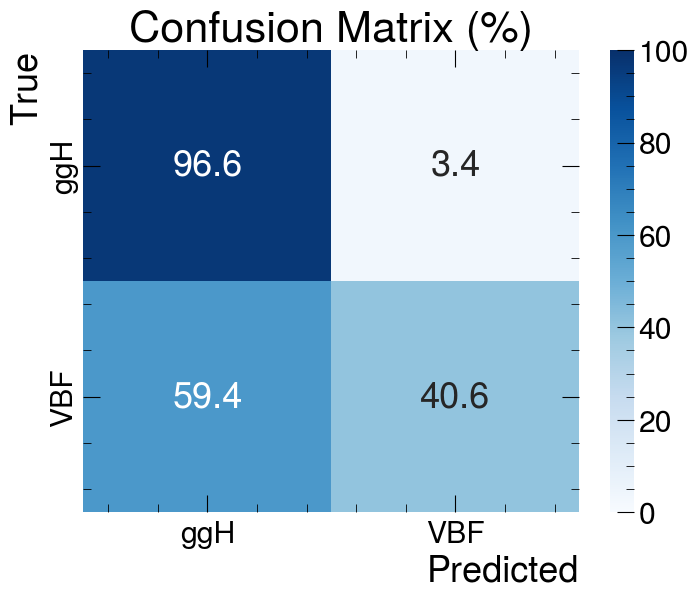

In [51]:
plot_confusion_matrix(Y, y_pred_kinematic)

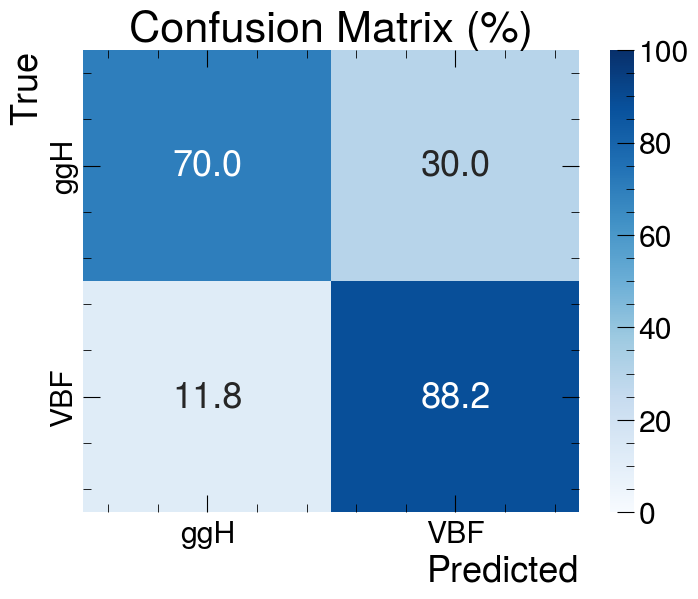

In [53]:
plot_confusion_matrix(y_test, y_pred)